In [61]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
from tqdm import tqdm

from sklearn.metrics import accuracy_score, log_loss
from sklearn.base import BaseEstimator, ClassifierMixin

In [ ]:
class MyNeuralNetrwork(BaseEstimator, ClassifierMixin):
    def __init__(self, hidden_layers =[16, 16, 16], learning_rate=0.1, n_iteration=1000):
        self.hidden_layers = hidden_layers
        self.dimensions = []
        self.learning_rate = learning_rate
        self.n_iteration = n_iteration
        
        self.parameters = {}
        self.activations = {}
        self.gradients = {}
        
        self.train_loss = []
        self.test_loss = []
        self.train_accuracy = []
        self.test_accuracy = []
        self.history = []
    
        self.m = None
        self.num_layers = 0
        
    def initialization(self, X):
        for i in range(1, self.num_layers +1):
            self.parameters['W' + str(i)] = np.random.randn(self.dimensions[i], self.dimensions[i - 1]) * np.sqrt(1 / self.dimensions[i - 1])
            self.parameters['b' + str(i)] = np.zeros((self.dimensions[i], 1))     
        self.m = X.shape[1]
            
    def forward_propagation(self, X):
        self.activations['A0'] = X
        for i in range(1, self.num_layers + 1):
            Z = self.parameters['W' + str(i)].dot(self.activations['A' + str(i-1)]) + self.parameters['b' + str(i)]
            self.activations['A' + str(i)] = 1/ (1 + np.exp(-Z))
            
        return self.activations['A' + str(self.num_layers)]
    
    def back_propagation(self, y):
        dZ = self.activations['A' + str(self.num_layers)] - y
        
        for i in reversed(range(1, self.num_layers + 1)):
            self.gradients['dW' + str(i)] = 1/self.m * np.dot(dZ, self.activations['A' + str(i-1)].T)
            self.gradients['db' + str(i)] = 1/self.m * np.sum(dZ, axis=1, keepdims = True)
            if i > 1:
                dZ = np.dot(self.parameters['W' + str(i)].T, dZ) * self.activations['A' + str(i-1)] * (1 - self.activations['A' + str(i-1)])
                
    def update(self):
        for i in range(1, self.num_layers + 1):
            self.parameters['W' + str(i)] -= self.learning_rate * self.gradients['dW' + str(i)]
            self.parameters['b' + str(i)] -= self.learning_rate * self.gradients['db' + str(i)]
            
    def learn(self, X, y, loss, accuracy):
        A_temp = self.forward_propagation(X)
        loss.append(log_loss(y.ravel(), A_temp.ravel()))

        accuracy.append(accuracy_score(y.ravel(), (A_temp >= 0.5).astype(int).ravel()))
        
            
    def fit(self, X_train, y_train, X_test=None, y_test=None):
        
        self.parameters, self.activations, self.gradients = {}, {}, {}
        self.train_loss, self.test_loss = [], []
        self.train_accuracy, self.test_accuracy = [], []
        
        X_train = np.asarray(X_train).T
        y_train = np.asarray(y_train).reshape(1, -1)

        has_test = X_test is not None
        if has_test:
            X_test = np.asarray(X_test).T
            y_test = np.asarray(y_test).reshape(1, -1)

        self.dimensions = [X_train.shape[0], *self.hidden_layers, 1]
        self.num_layers = len(self.dimensions) - 1
        self.initialization(X_train)

        for i in tqdm(range(self.n_iteration)):
            self.forward_propagation(X_train)
            self.back_propagation(y_train)
            self.update()

            self.learn(X_train, y_train, self.train_loss, self.train_accuracy)
            if has_test:
                self.learn(X_test, y_test, self.test_loss, self.test_accuracy)
        return self
    
    def evaluation(self):
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(self.train_loss, label='train loss')
        plt.plot(self.test_loss, label='test loss')
        plt.legend()
        plt.subplot(1, 2, 2)
        plt.plot(self.train_accuracy, label='train acc')
        plt.plot(self.test_accuracy, label='test acc')
        plt.legend()
        plt.show()
               
    def predict(self, X):
        A = self.forward_propagation(np.asarray(X).T)
        return (A >= 0.5).astype(int).ravel()
    
    @property
    def acc(self):
        model_accuracy = self.test_accuracy[-1] * 100
        return round(model_accuracy, 2)
    
    @property
    def loss(self):
        model_loss = self.test_loss[-1] * 100
        return float(round(model_loss, 2))

In [54]:
def data_preprocessing(raw_data):
    data_normalised = raw_data / 255.0
    data = data_normalised.reshape(data_normalised.shape[0], -1)
    
    return data 

def load_data(data_path):
    train_path = data_path + 'trainset.hdf5'
    test_path = data_path + 'testset.hdf5'
    
    with h5py.File(train_path, "r") as raw_trainset:
        raw_X_train = np.array(raw_trainset["X_train"][:])
        y_train = np.array(raw_trainset["Y_train"][:])
        
    with h5py.File(test_path, "r") as raw_testset:
        raw_X_test = np.array(raw_testset["X_test"][:])
        y_test = np.array(raw_testset["Y_test"][:])
        
    X_train = data_preprocessing(raw_X_train)
    X_test = data_preprocessing(raw_X_test)
    
    return X_train,y_train, X_test, y_test


In [47]:
data_path = '/content/datasets/'
X_train, y_train, X_test, y_test = load_data(data_path)

In [63]:
neuron = MyNeuralNetrwork(hidden_layers=[32, 32, 32], learning_rate=0.01, n_iteration=1000)

In [64]:
model= neuron.fit(X_train, y_train, X_test, y_test)

100%|██████████| 1000/1000 [00:49<00:00, 20.14it/s]


Accuracy: 54.0 %
Loss: 69.31


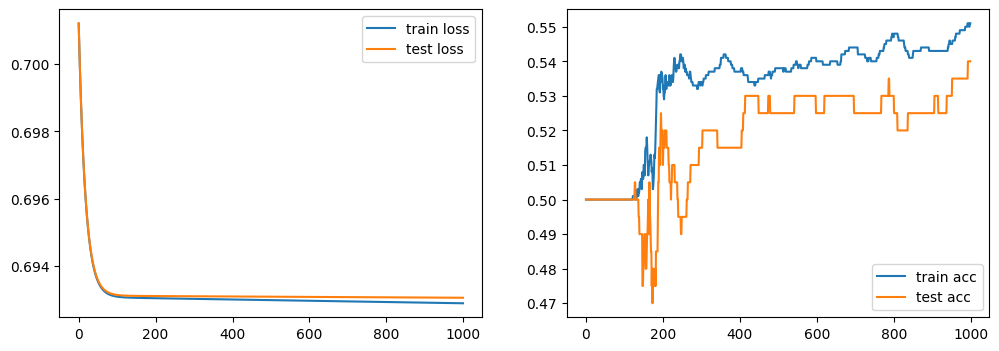

In [60]:
print(f'Accuracy: {model.acc} %')
print(f'Loss: {model.loss}')
neuron.evaluation()